# Лабораторная работа №2. Линейная регрессия

**Датасет:** `train (2).csv` (Ames Housing).  
**Целевая переменная:** `SalePrice` — цена продажи дома.

В наборе 1460 наблюдений, 81 столбец (включая `Id` и целевую переменную), 79 исходных признаков после исключения идентификатора. Есть числовые и категориальные признаки, а также естественные пропуски. Пропуски в некоторых полях означают отсутствие объекта (например, бассейна или подвала), а не ошибку измерения.


## 0. Импорт библиотек и загрузка данных

In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from scipy import stats
from scipy.stats import t
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder, StandardScaler, MinMaxScaler, RobustScaler, KBinsDiscretizer
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.model_selection import train_test_split, RepeatedKFold, KFold, cross_val_score
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from sklearn.inspection import permutation_importance
from sklearn.ensemble import IsolationForest
from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.stats.diagnostic import het_breuschpagan, het_white, linear_reset
from statsmodels.stats.stattools import durbin_watson
from statsmodels.nonparametric.smoothers_lowess import lowess
import statsmodels.api as sm
from IPython.display import display

SEED = 42
np.random.seed(SEED)

df = pd.read_csv('../data/train (2).csv')

TARGET = "SalePrice"
assert TARGET in df.columns, f"В датасете нет целевой переменной {TARGET}"
df = df.drop(columns=["Id"], errors="ignore")
X = df.drop(columns=[TARGET]).copy()
y = df[TARGET].astype(float).copy()

print("Размер:", df.shape)
print("Число числовых признаков:", X.select_dtypes(include=np.number).shape[1])
print("Число категориальных признаков:", X.select_dtypes(exclude=np.number).shape[1])
print("Пропусков всего:", int(df.isna().sum().sum()))
display(df.head())

Размер: (1460, 80)
Число числовых признаков: 36
Число категориальных признаков: 43
Пропусков всего: 7829


,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,LotConfig,LandSlope,Neighborhood,Condition1,Condition2,BldgType,HouseStyle,OverallQual,OverallCond,YearBuilt,YearRemodAdd,RoofStyle,RoofMatl,Exterior1st,Exterior2nd,MasVnrType,MasVnrArea,ExterQual,ExterCond,Foundation,BsmtQual,BsmtCond,BsmtExposure,BsmtFinType1,BsmtFinSF1,BsmtFinType2,BsmtFinSF2,BsmtUnfSF,TotalBsmtSF,Heating,HeatingQC,CentralAir,Electrical,1stFlrSF,2ndFlrSF,LowQualFinSF,GrLivArea,BsmtFullBath,BsmtHalfBath,FullBath,HalfBath,BedroomAbvGr,KitchenAbvGr,KitchenQual,TotRmsAbvGrd,Functional,Fireplaces,FireplaceQu,GarageType,GarageYrBlt,GarageFinish,GarageCars,GarageArea,GarageQual,GarageCond,PavedDrive,WoodDeckSF,OpenPorchSF,EnclosedPorch,3SsnPorch,ScreenPorch,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,60,RL,65.0,8450,Pave,NaN,Reg,Lvl,AllPub,Inside,Gtl,CollgCr,Norm,Norm,1Fam,2Story,7,5,2003,2003,Gable,CompShg,VinylSd,VinylSd,BrkFace,196.0,Gd,TA,PConc,Gd,TA,No,GLQ,706,Unf,0,150,856,GasA,Ex,Y,SBrkr,856,854,0,1710,1,0,2,1,3,1,Gd,8,Typ,0,NaN,Attchd,2003.0,RFn,2,548,TA,TA,Y,0,61,0,0,0,0,NaN,NaN,NaN,0,2,2008,WD,Normal,208500
1,20,RL,80.0,9600,Pave,NaN,Reg,Lvl,AllPub,FR2,Gtl,Veenker,Feedr,Norm,1Fam,1Story,6,8,1976,1976,Gable,CompShg,MetalSd,MetalSd,NaN,0.0,TA,TA,CBlock,Gd,TA,Gd,ALQ,978,Unf,0,284,1262,GasA,Ex,Y,SBrkr,1262,0,0,1262,0,1,2,0,3,1,TA,6,Typ,1,TA,Attchd,1976.0,RFn,2,460,TA,TA,Y,298,0,0,0,0,0,NaN,NaN,NaN,0,5,2007,WD,Normal,181500
2,60,RL,68.0,11250,Pave,NaN,IR1,Lvl,AllPub,Inside,Gtl,CollgCr,Norm,Norm,1Fam,2Story,7,5,2001,2002,Gable,CompShg,VinylSd,VinylSd,BrkFace,162.0,Gd,TA,PConc,Gd,TA,Mn,GLQ,486,Unf,0,434,920,GasA,Ex,Y,SBrkr,920,866,0,1786,1,0,2,1,3,1,Gd,6,Typ,1,TA,Attchd,2001.0,RFn,2,608,TA,TA,Y,0,42,0,0,0,0,NaN,NaN,NaN,0,9,2008,WD,Normal,223500
3,70,RL,60.0,9550,Pave,NaN,IR1,Lvl,AllPub,Corner,Gtl,Crawfor,Norm,Norm,1Fam,2Story,7,5,1915,1970,Gable,CompShg,Wd Sdng,Wd Shng,NaN,0.0,TA,TA,BrkTil,TA,Gd,No,ALQ,216,Unf,0,540,756,GasA,Gd,Y,SBrkr,961,756,0,1717,1,0,1,0,3,1,Gd,7,Typ,1,Gd,Detchd,1998.0,Unf,3,642,TA,TA,Y,0,35,272,0,0,0,NaN,NaN,NaN,0,2,2006,WD,Abnorml,140000
4,60,RL,84.0,14260,Pave,NaN,IR1,Lvl,AllPub,FR2,Gtl,NoRidge,Norm,Norm,1Fam,2Story,8,5,2000,2000,Gable,CompShg,VinylSd,VinylSd,BrkFace,350.0,Gd,TA,PConc,Gd,TA,Av,GLQ,655,Unf,0,490,1145,GasA,Ex,Y,SBrkr,1145,1053,0,2198,1,0,2,1,4,1,Gd,9,Typ,1,TA,Attchd,2000.0,RFn,3,836,TA,TA,Y,192,84,0,0,0,0,NaN,NaN,NaN,0,12,2008,WD,Normal,250000


## 1. Диагностика данных

### 1.1. Распределения признаков и целевой переменной

,count,mean,std,min,5%,25%,50%,75%,95%,max,skew,kurtosis
MSSubClass,1460.0,56.897260,42.300571,20.0,20.00,20.00,50.0,70.00,160.00,190.0,1.407657,1.580188
LotFrontage,1201.0,70.049958,24.284752,21.0,34.00,59.00,69.0,80.00,107.00,313.0,2.163569,17.452867
LotArea,1460.0,10516.828082,9981.264932,1300.0,3311.70,7553.50,9478.5,11601.50,17401.15,215245.0,12.207688,203.243271
OverallQual,1460.0,6.099315,1.382997,1.0,4.00,5.00,6.0,7.00,8.00,10.0,0.216944,0.096293
OverallCond,1460.0,5.575342,1.112799,1.0,4.00,5.00,5.0,6.00,8.00,9.0,0.693067,1.106413
YearBuilt,1460.0,1971.267808,30.202904,1872.0,1916.00,1954.00,1973.0,2000.00,2007.00,2010.0,-0.613461,-0.439552
YearRemodAdd,1460.0,1984.865753,20.645407,1950.0,1950.00,1967.00,1994.0,2004.00,2007.00,2010.0,-0.503562,-1.272245
MasVnrArea,1452.0,103.685262,181.066207,0.0,0.00,0.00,0.0,166.00,456.00,1600.0,2.669084,10.082417
BsmtFinSF1,1460.0,443.639726,456.098091,0.0,0.00,0.00,383.5,712.25,1274.00,5644.0,1.685503,11.118236
BsmtFinSF2,1460.0,46.549315,161.319273,0.0,0.00,0.00,0.0,0.00,396.20,1474.0,4.255261,20.113338


,SalePrice,skew,kurtosis
count,1460.000000,1.882876,6.536282
mean,180921.195890,1.882876,6.536282
std,79442.502883,1.882876,6.536282
min,34900.000000,1.882876,6.536282
5%,88000.000000,1.882876,6.536282
25%,129975.000000,1.882876,6.536282
50%,163000.000000,1.882876,6.536282
75%,214000.000000,1.882876,6.536282
95%,326100.000000,1.882876,6.536282
max,755000.000000,1.882876,6.536282



MSZoning:


,frequency
MSZoning,
RL,1151
RM,218
FV,65
RH,16
C (all),10



Street:


,frequency
Street,
Pave,1454
Grvl,6


... (78 outputs left out)


SaleType:


,frequency
SaleType,
WD,1267
New,122
COD,43
ConLD,9
ConLI,5
ConLw,5
CWD,4
Oth,3
Con,2



SaleCondition:


,frequency
SaleCondition,
Normal,1198
Partial,125
Abnorml,101
Family,20
Alloca,12
AdjLand,4


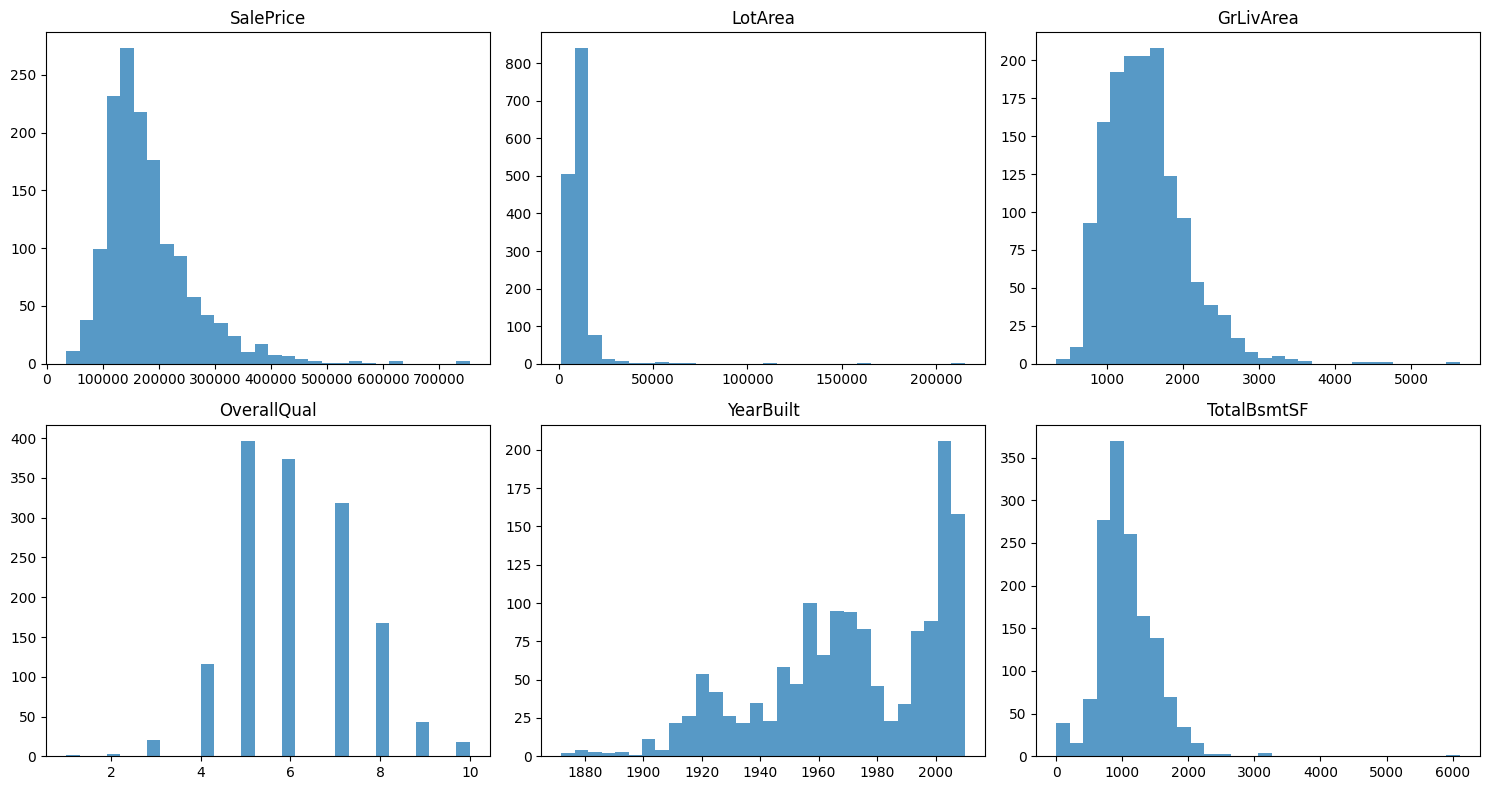

In [2]:
num_cols = X.select_dtypes(include=np.number).columns.tolist()
cat_cols = X.select_dtypes(exclude=np.number).columns.tolist()

# Сводные статистики числовых признаков: квантили, асимметрия и эксцесс.
numeric_description = X[num_cols].describe(percentiles=[.05, .25, .5, .75, .95]).T
numeric_description["skew"] = X[num_cols].skew()
numeric_description["kurtosis"] = X[num_cols].kurtosis()
display(numeric_description)

target_description = y.describe(percentiles=[.05, .25, .5, .75, .95]).to_frame("SalePrice")
target_description["skew"] = y.skew()
target_description["kurtosis"] = y.kurtosis()
display(target_description)

# Частоты категориальных значений (первые 15 категорий в каждом поле).
for col in cat_cols:
    print(f"\n{col}:")
    display(X[col].value_counts(dropna=False).head(15).to_frame("frequency"))

# Гистограмма цели и несколько наиболее информативных числовых распределений.
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, col in zip(axes.flat, ["SalePrice", "LotArea", "GrLivArea", "OverallQual", "YearBuilt", "TotalBsmtSF"]):
    series = y if col == TARGET else X[col]
    ax.hist(series.dropna(), bins=30, alpha=0.75)
    ax.set_title(col)
plt.tight_layout()
plt.show()

### 1.2. Разделение train/validation/test до предобработки

In [3]:
X_train, X_temp, y_train, y_temp = train_test_split(
    X, y, test_size=0.30, random_state=SEED
)
X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.50, random_state=SEED
)
print("Train:", X_train.shape, "Validation:", X_val.shape, "Test:", X_test.shape)

# Пример: медианы вычисляются только по train, затем применяются к val/test.
train_medians = X_train[num_cols].median()
print("Пример медиан, рассчитанных только на train:")
display(train_medians.head())

print("Доля пропусков до импутации:")
display(X_train.isna().mean().sort_values(ascending=False).head(12))

Train: (1022, 79) Validation: (219, 79) Test: (219, 79)
Пример медиан, рассчитанных только на train:


MSSubClass       50.0
LotFrontage      70.0
LotArea        9600.0
OverallQual       6.0
OverallCond       5.0
dtype: float64

Доля пропусков до импутации:


PoolQC          0.995108
MiscFeature     0.960861
Alley           0.935421
Fence           0.802348
MasVnrType      0.577299
FireplaceQu     0.476517
LotFrontage     0.185910
GarageQual      0.052838
GarageFinish    0.052838
GarageType      0.052838
GarageYrBlt     0.052838
GarageCond      0.052838
dtype: float64

**Почему иначе возникает утечка:** если вычислить медианы, границы выбросов, параметры масштабирования или частоты категорий на полном датасете, информация из validation/test повлияет на преобразование обучающих данных. Тогда оценка качества будет оптимистичной и не будет имитировать прогноз для новых наблюдений.

### 1.3. Две стратегии обработки пропусков: удаление строк и импутация

In [4]:
def make_preprocessor(strategy="median", encoding="onehot", scaler=None):
    numeric_transformers = [("imputer", SimpleImputer(strategy=strategy))]
    if scaler is not None:
        numeric_transformers.append(("scaler", scaler))
    numeric_pipe = Pipeline(numeric_transformers)

    if encoding == "onehot":
        cat_pipe = Pipeline([
            ("imputer", SimpleImputer(strategy="most_frequent")),
            ("encoder", OneHotEncoder(handle_unknown="ignore"))
        ])
    elif encoding == "ordinal":
        cat_pipe = Pipeline([
            ("imputer", SimpleImputer(strategy="most_frequent")),
            ("encoder", OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-1))
        ])
    else:
        raise ValueError("encoding должен быть onehot или ordinal")

    return ColumnTransformer([
        ("num", numeric_pipe, num_cols),
        ("cat", cat_pipe, cat_cols)
    ])

# Стратегия A: удалить строки с любыми пропусками. Это может резко уменьшить выборку.
train_complete = X_train.notna().all(axis=1)
val_complete = X_val.notna().all(axis=1)
drop_model = Pipeline([
    ("prep", make_preprocessor(strategy="median")),
    ("model", LinearRegression())
])
if train_complete.sum() >= 30 and val_complete.sum() >= 10:
    drop_model.fit(X_train.loc[train_complete], y_train.loc[train_complete])
    pred_drop = drop_model.predict(X_val.loc[val_complete])
    rmse_drop = mean_squared_error(y_val.loc[val_complete], pred_drop) ** 0.5
    print("Удаление строк: осталось train =", train_complete.sum(),
          ", validation =", val_complete.sum(), ", RMSE =", round(rmse_drop, 2))
else:
    rmse_drop = np.nan
    print("Удаление строк оставляет слишком мало наблюдений; стратегия непригодна.")

# Стратегия B: числовые медианы и категориальные моды.
median_model = Pipeline([
    ("prep", make_preprocessor(strategy="median")),
    ("model", LinearRegression())
])
median_model.fit(X_train, y_train)
pred_median = median_model.predict(X_val)
rmse_median = mean_squared_error(y_val, pred_median) ** 0.5
print("Импутация: train =", len(X_train), ", validation =", len(X_val),
      ", RMSE =", round(rmse_median, 2))
print("Выбор: импутация сохраняет больше данных; пропуски в Ames Housing часто имеют смысл отсутствия объекта.")

Удаление строк оставляет слишком мало наблюдений; стратегия непригодна.
Импутация: train = 1022 , validation = 219 , RMSE = 28483.68
Выбор: импутация сохраняет больше данных; пропуски в Ames Housing часто имеют смысл отсутствия объекта.


### 1.4. Выбросы: IQR и Isolation Forest (без автоматического удаления)

In [5]:
# IQR по числовым признакам на train.
q1 = X_train[num_cols].quantile(.25)
q3 = X_train[num_cols].quantile(.75)
iqr = q3 - q1
iqr_mask = ((X_train[num_cols] < (q1 - 1.5 * iqr)) |
            (X_train[num_cols] > (q3 + 1.5 * iqr)))
iqr_counts = iqr_mask.sum().sort_values(ascending=False)
display(iqr_counts.head(15).to_frame("IQR_outliers"))

# Isolation Forest обучается только на числовой части train после медианной импутации.
iso_prep = SimpleImputer(strategy="median")
Xtr_num_imp = iso_prep.fit_transform(X_train[num_cols])
iso = IsolationForest(contamination=0.03, random_state=SEED)
iso_labels = iso.fit_predict(Xtr_num_imp)
print("Isolation Forest: потенциальных выбросов:", int((iso_labels == -1).sum()))

# Осмотр верхних значений цены и площади: экстремум не равен ошибке.
display(df.nlargest(10, TARGET)[["SalePrice", "GrLivArea", "OverallQual", "YearBuilt"]])
print("Интерпретация: IQR/Isolation Forest выявляют необычные наблюдения, но сами по себе не доказывают ошибку.")

,IQR_outliers
EnclosedPorch,138
BsmtFinSF2,111
ScreenPorch,86
OverallCond,85
MSSubClass,75
GarageArea,73
LotFrontage,64
MasVnrArea,62
BsmtHalfBath,60
OpenPorchSF,54


Isolation Forest: потенциальных выбросов: 31


,SalePrice,GrLivArea,OverallQual,YearBuilt
691,755000,4316,10,1994
1182,745000,4476,10,1996
1169,625000,3627,10,1995
898,611657,2364,9,2009
803,582933,2822,9,2008
1046,556581,2868,9,2005
440,555000,2402,10,2008
769,538000,3279,8,2003
178,501837,2234,9,2008
798,485000,3140,9,2008


Интерпретация: IQR/Isolation Forest выявляют необычные наблюдения, но сами по себе не доказывают ошибку.


### 1.5. A1 — влияет ли удаление выбросов на RMSE?

In [6]:
# Эксперимент проводится на train; правило IQR для целевой переменной рассчитано только на train.
q1_y, q3_y = y_train.quantile([.25, .75])
iqr_y = q3_y - q1_y
keep_y = y_train.between(q1_y - 1.5*iqr_y, q3_y + 1.5*iqr_y)

model_all = Pipeline([("prep", make_preprocessor()), ("model", LinearRegression())])
model_trim = Pipeline([("prep", make_preprocessor()), ("model", LinearRegression())])
model_all.fit(X_train, y_train)
model_trim.fit(X_train.loc[keep_y], y_train.loc[keep_y])

p_all = model_all.predict(X_test)
p_trim = model_trim.predict(X_test)
rmse_all = mean_squared_error(y_test, p_all)**0.5
rmse_trim = mean_squared_error(y_test, p_trim)**0.5
print(f"RMSE без удаления: {rmse_all:.2f}")
print(f"RMSE после удаления train-выбросов SalePrice: {rmse_trim:.2f}")
print(f"Изменение RMSE (trim - all): {rmse_trim-rmse_all:.2f}")
print("Тестовая выборка не очищалась: сравнение показывает обобщение на исходное распределение.")

RMSE без удаления: 32566.47
RMSE после удаления train-выбросов SalePrice: 40442.11
Изменение RMSE (trim - all): 7875.64
Тестовая выборка не очищалась: сравнение показывает обобщение на исходное распределение.


## 2. Признаки и предобработка

### 2.1. One-hot, ordinal и target/mean encoding

In [7]:
# Сравнение one-hot и ordinal на одном validation split.
enc_results = {}
for enc in ["onehot", "ordinal"]:
    pipe = Pipeline([("prep", make_preprocessor(encoding=enc)), ("model", LinearRegression())])
    pipe.fit(X_train, y_train)
    pv = pipe.predict(X_val)
    enc_results[enc] = mean_squared_error(y_val, pv)**0.5
print("RMSE:", enc_results)

# OOF target encoding для одного категориального признака (Neighborhood).
# Внутри каждого фолда средние считаются только по его обучающей части.
from sklearn.model_selection import KFold
target_col = "Neighborhood" if "Neighborhood" in cat_cols else cat_cols[0]
def oof_target_encode(train_series, target, valid_series, n_splits=5, seed=SEED):
    train_series = train_series.fillna("__MISSING__").astype(str).reset_index(drop=True)
    target = pd.Series(target).reset_index(drop=True)
    valid_series = valid_series.fillna("__MISSING__").astype(str)
    oof = pd.Series(index=train_series.index, dtype=float)
    kf = KFold(n_splits=n_splits, shuffle=True, random_state=seed)
    global_mean = target.mean()
    for tr_idx, va_idx in kf.split(train_series):
        means = target.iloc[tr_idx].groupby(train_series.iloc[tr_idx]).mean()
        oof.iloc[va_idx] = train_series.iloc[va_idx].map(means).fillna(global_mean).values
    full_means = target.groupby(train_series).mean()
    valid_encoded = valid_series.map(full_means).fillna(global_mean)
    return oof.to_numpy().reshape(-1, 1), valid_encoded.to_numpy().reshape(-1, 1)

te_train, te_val = oof_target_encode(X_train[target_col], y_train, X_val[target_col])
# Для изоляции эффекта кодирования используем только данный категориальный столбец.
te_model = LinearRegression().fit(te_train, y_train)
te_pred = te_model.predict(te_val)
print("OOF target encoding, один признак:", target_col,
      "| RMSE validation =", round(mean_squared_error(y_val, te_pred)**0.5, 2))

# Демонстрация утечки: mean target по категории на всей выборке, включая оцениваемые строки.
full_means = pd.concat([X_train[target_col].astype(str), X_val[target_col].astype(str)]).groupby(
    pd.concat([X_train[target_col].astype(str), X_val[target_col].astype(str)])
).size()  # структура категорий для иллюстрации ниже
leaky_train = y_train.groupby(X_train[target_col].astype(str)).mean()
leaky_val = X_val[target_col].astype(str).map(leaky_train).fillna(y_train.mean()).to_numpy().reshape(-1,1)
leaky_train_encoded = X_train[target_col].astype(str).map(leaky_train).to_numpy().reshape(-1,1)
leaky_model = LinearRegression().fit(leaky_train_encoded, y_train)
print("Утечка особенно сильна при вычислении среднего target по тем же объектам, на которых оценивается кодирование.")
print("OOF encoding предпочтителен: каждое train-наблюдение кодируется без собственного target.")

RMSE: {'onehot': 28483.68109000785, 'ordinal': 26616.846032750498}
OOF target encoding, один признак: Neighborhood | RMSE validation = 47365.57
Утечка особенно сильна при вычислении среднего target по тем же объектам, на которых оценивается кодирование.
OOF encoding предпочтителен: каждое train-наблюдение кодируется без собственного target.


### 2.2. Биннинг: uniform, quantile, k-means; 3/5/10/20 бинов

,strategy,n_bins,encoding,RMSE
14,quantile,20,ordinal,54798.477393
22,kmeans,20,ordinal,54930.496114
20,kmeans,10,ordinal,55097.801074
12,quantile,10,ordinal,55123.510085
13,quantile,10,onehot,55131.688597
7,uniform,20,onehot,55232.444337
23,kmeans,20,onehot,55265.157789
15,quantile,20,onehot,55270.175699
6,uniform,20,ordinal,55721.586514
21,kmeans,10,onehot,55731.291763


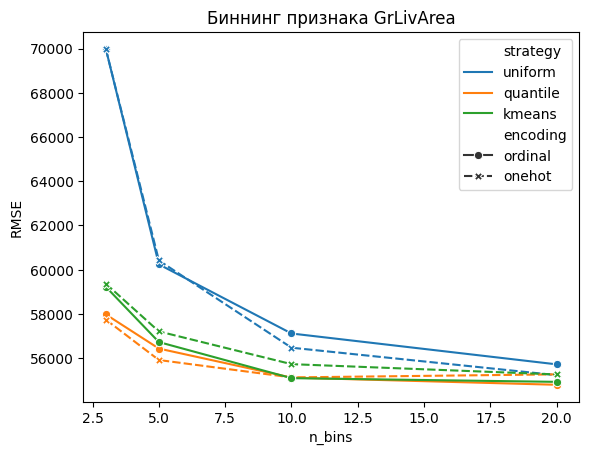

In [8]:
bin_feature = "GrLivArea"
bin_rows = []
for strategy in ["uniform", "quantile", "kmeans"]:
    for n_bins in [3, 5, 10, 20]:
        for encoding in ["ordinal", "onehot"]:
            prep = ColumnTransformer([
                ("bin", Pipeline([
                    ("imputer", SimpleImputer(strategy="median")),
                    ("binning", KBinsDiscretizer(n_bins=n_bins, encode=encoding, strategy=strategy,
                                                subsample=None, random_state=SEED))
                ]), [bin_feature])
            ])
            pipe = Pipeline([("prep", prep), ("model", LinearRegression())])
            pipe.fit(X_train[[bin_feature]], y_train)
            pred = pipe.predict(X_val[[bin_feature]])
            bin_rows.append([strategy, n_bins, encoding, mean_squared_error(y_val, pred)**0.5])
bin_results = pd.DataFrame(bin_rows, columns=["strategy","n_bins","encoding","RMSE"])
display(bin_results.sort_values("RMSE").head(12))
sns.lineplot(data=bin_results, x="n_bins", y="RMSE", hue="strategy", style="encoding", markers=True)
plt.title(f"Биннинг признака {bin_feature}")
plt.show()

### 2.3. B1 — монотонность и биннинг

In [9]:
# Спирменова корреляция между признаком и остатками простой линейной модели:
# чем ближе |rho| к 1, тем сильнее монотонная связь остатка с признаком.
candidate_features = [c for c in ["GrLivArea", "LotArea", "OverallQual", "YearBuilt", "GarageArea"] if c in num_cols]
mono_rows = []
for feat in candidate_features:
    tmp = X_train[[feat]].copy()
    med = tmp[feat].median()
    xx = tmp[feat].fillna(med).to_numpy().reshape(-1,1)
    yy = y_train.to_numpy()
    simple = LinearRegression().fit(xx, yy)
    resid = yy - simple.predict(xx)
    rho, pval = stats.spearmanr(tmp[feat].fillna(med), resid)
    mono_rows.append([feat, rho, pval, abs(rho)])
mono_df = pd.DataFrame(mono_rows, columns=["feature","spearman_rho_resid","p_value","nonmonotonicity_proxy"])
display(mono_df)

# Сравнение raw continuous vs quantile-bin one-hot на тех же отдельных признаках.
b1_rows = []
for feat in candidate_features:
    raw = Pipeline([("imp", SimpleImputer(strategy="median")), ("sc", StandardScaler()), ("lr", LinearRegression())])
    raw.fit(X_train[[feat]], y_train)
    raw_rmse = mean_squared_error(y_val, raw.predict(X_val[[feat]]))**0.5
    binned = Pipeline([
        ("imp", SimpleImputer(strategy="median")),
        ("bin", KBinsDiscretizer(n_bins=5, encode="onehot", strategy="quantile", subsample=None)),
        ("lr", LinearRegression())
    ])
    binned.fit(X_train[[feat]], y_train)
    bin_rmse = mean_squared_error(y_val, binned.predict(X_val[[feat]]))**0.5
    b1_rows.append([feat, raw_rmse, bin_rmse, bin_rmse-raw_rmse])
display(pd.DataFrame(b1_rows, columns=["feature","RMSE_raw","RMSE_binned","delta_binned_minus_raw"]))
print("B1 оценивается как тенденция на выбранных признаках; небольшая выборка признаков не доказывает универсальный закон.")

,feature,spearman_rho_resid,p_value,nonmonotonicity_proxy
0,GrLivArea,0.014966,6.327256e-01,0.014966
1,LotArea,0.345636,4.751769e-30,0.345636
2,OverallQual,-0.131577,2.447630e-05,0.131577
3,YearBuilt,0.000871,9.778187e-01,0.000871
4,GarageArea,-0.046741,1.353752e-01,0.046741


,feature,RMSE_raw,RMSE_binned,delta_binned_minus_raw
0,GrLivArea,54872.669830,55917.751498,1045.081668
1,LotArea,75792.207174,67514.188592,-8278.018582
2,OverallQual,41638.451229,53181.788896,11543.337667
3,YearBuilt,65610.463445,62003.567335,-3606.896110
4,GarageArea,61994.951525,60431.489120,-1563.462405


B1 оценивается как тенденция на выбранных признаках; небольшая выборка признаков не доказывает универсальный закон.


### 2.4. Корреляции, VIF, число обусловленности и bootstrap-устойчивость

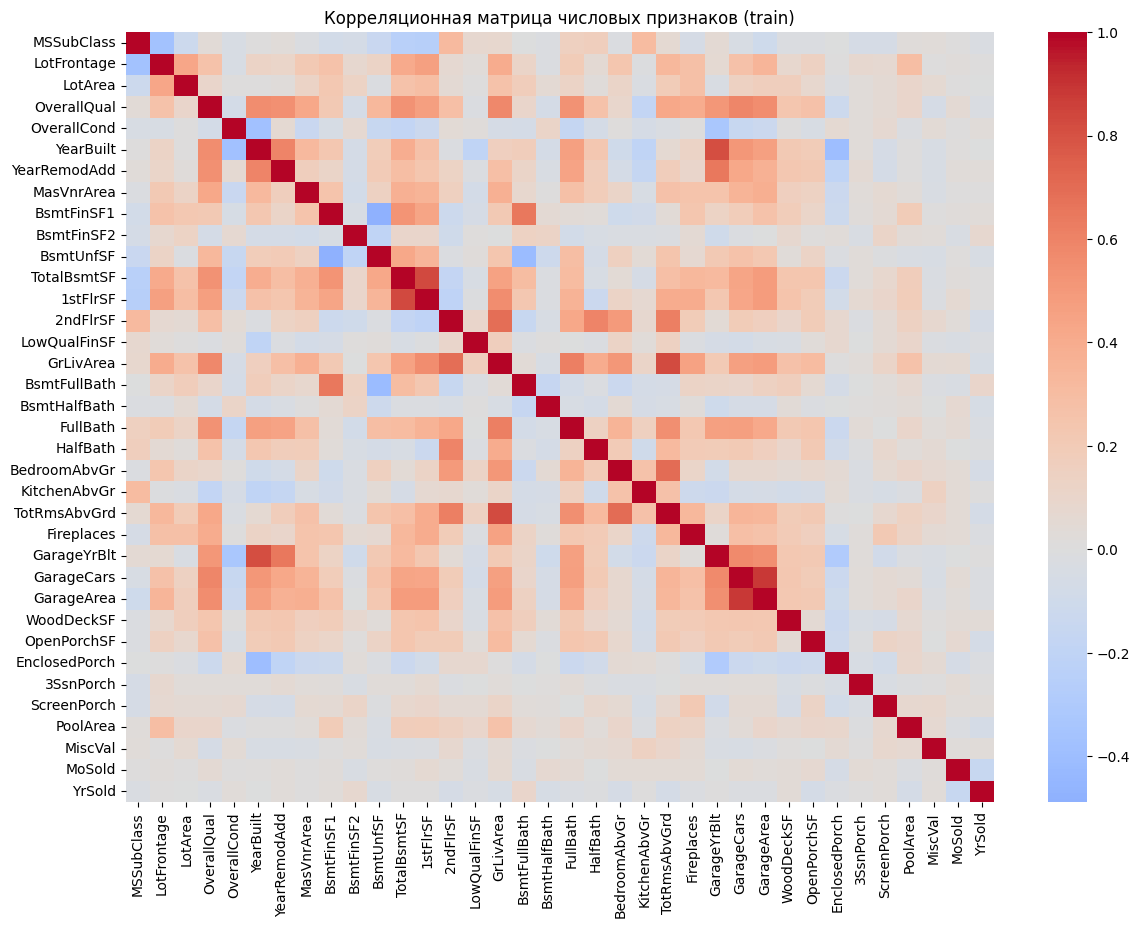

,feature,VIF
6,YearBuilt,8090.886754
7,YearRemodAdd,7910.742054
0,OverallQual,48.084196
3,1stFlrSF,37.901215
5,GarageCars,34.967504
4,GarageArea,30.527081
2,TotalBsmtSF,24.715726
1,GrLivArea,24.060835
9,FullBath,18.085340
8,LotArea,2.159355


Число обусловленности стандартизованной матрицы: 6.6724652225310965


,feature,coef_mean,coef_std,std_over_abs_mean
4,GarageArea,8.957564,25.726814,2.872077
2,TotalBsmtSF,10.655547,14.094543,1.322742
5,GarageCars,12999.954126,9323.134393,0.717167
9,FullBath,-6943.572007,4838.932132,0.696894
3,1stFlrSF,12.721448,6.949696,0.546298
8,LotArea,0.651818,0.167669,0.257233
1,GrLivArea,45.621464,10.373137,0.227374
6,YearBuilt,303.354717,64.049791,0.211138
7,YearRemodAdd,307.427587,62.572258,0.203535
0,OverallQual,20217.528619,2090.493985,0.103400


Признаки с высоким VIF и/или большим разбросом bootstrap-коэффициентов разумно объединять либо исключать.


In [10]:
# Корреляции числовых признаков (на train).
corr = X_train[num_cols].corr()
plt.figure(figsize=(14, 10))
sns.heatmap(corr, cmap="coolwarm", center=0)
plt.title("Корреляционная матрица числовых признаков (train)")
plt.show()

# VIF для ограниченного набора числовых признаков с заполнением медианой.
vif_features = [c for c in ["OverallQual","GrLivArea","TotalBsmtSF","1stFlrSF","GarageArea",
                            "GarageCars","YearBuilt","YearRemodAdd","LotArea","FullBath"] if c in num_cols]
vif_data = SimpleImputer(strategy="median").fit_transform(X_train[vif_features])
vif_frame = pd.DataFrame({
    "feature": vif_features,
    "VIF": [variance_inflation_factor(vif_data, i) for i in range(len(vif_features))]
}).sort_values("VIF", ascending=False)
display(vif_frame)
condition_number = np.linalg.cond(StandardScaler().fit_transform(vif_data))
print("Число обусловленности стандартизованной матрицы:", condition_number)

# Bootstrap коэффициентов для оценки нестабильности при мультиколлинеарности.
boot_coefs = []
rng = np.random.default_rng(SEED)
for b in range(200):
    idx = rng.integers(0, len(vif_data), len(vif_data))
    m = LinearRegression().fit(vif_data[idx], y_train.iloc[idx])
    boot_coefs.append(m.coef_)
boot_coefs = np.asarray(boot_coefs)
coef_stability = pd.DataFrame({
    "feature": vif_features,
    "coef_mean": boot_coefs.mean(axis=0),
    "coef_std": boot_coefs.std(axis=0),
    "std_over_abs_mean": boot_coefs.std(axis=0)/(np.abs(boot_coefs.mean(axis=0))+1e-9)
}).sort_values("std_over_abs_mean", ascending=False)
display(coef_stability)
print("Признаки с высоким VIF и/или большим разбросом bootstrap-коэффициентов разумно объединять либо исключать.")

## 3. Модели

### 3.1. Простая линейная регрессия: несколько пар, остатки и тесты

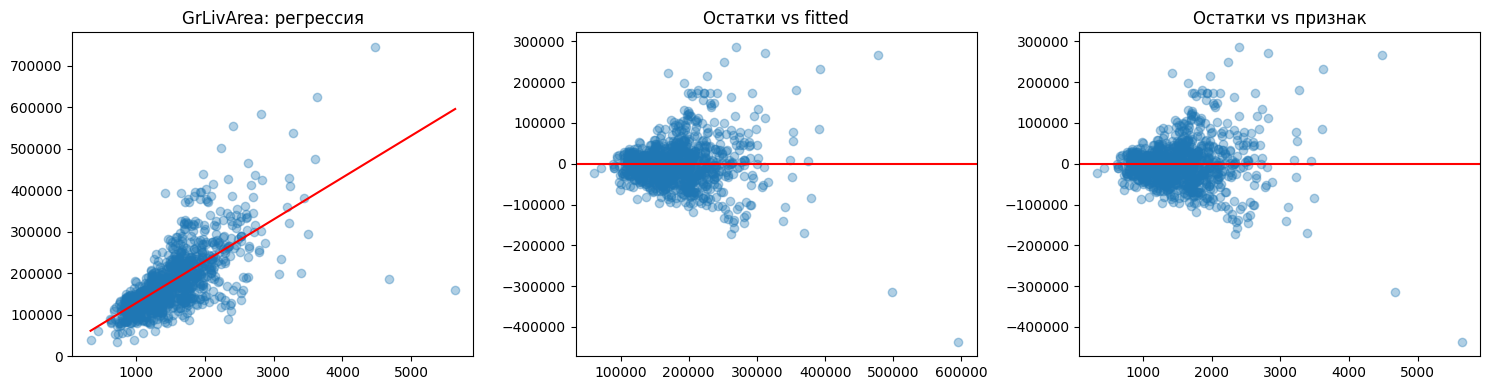


GrLivArea: коэффициенты и 95% ДИ


,CI_low,CI_high
const,16703.562894,37770.995438
x1,94.245301,107.260212


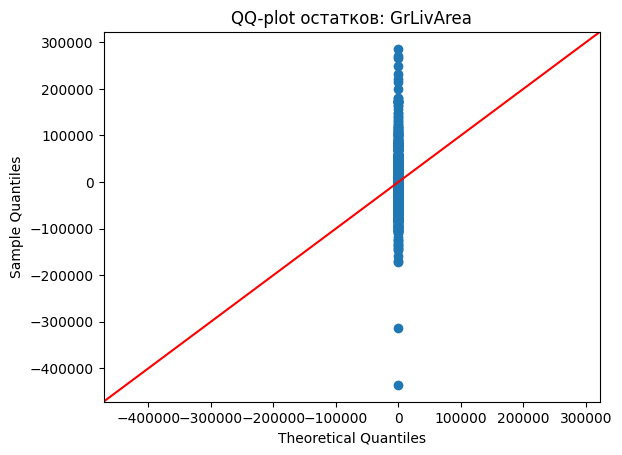

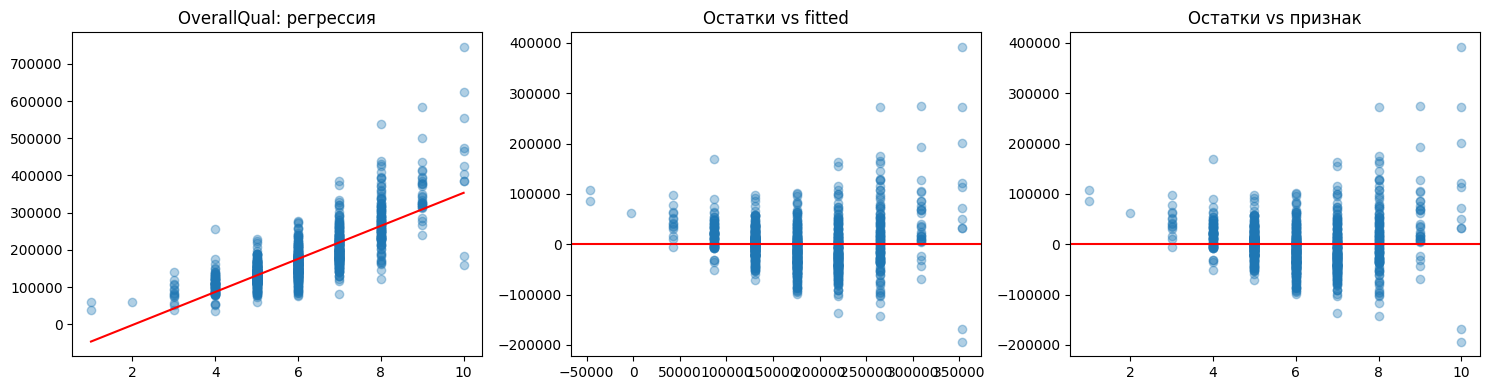


OverallQual: коэффициенты и 95% ДИ


,CI_low,CI_high
const,-104395.581326,-77324.154841
x1,42257.774283,46568.780781


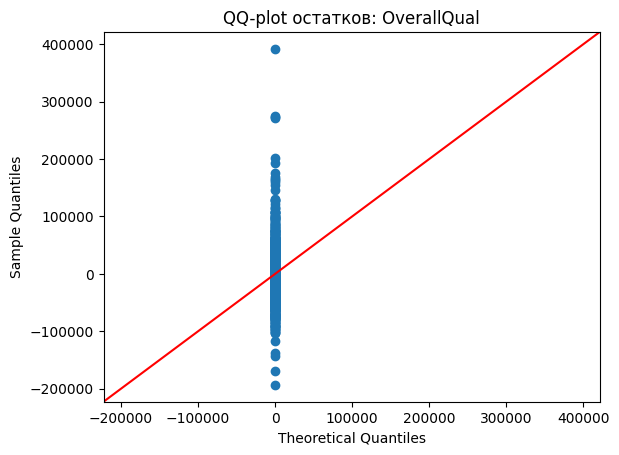

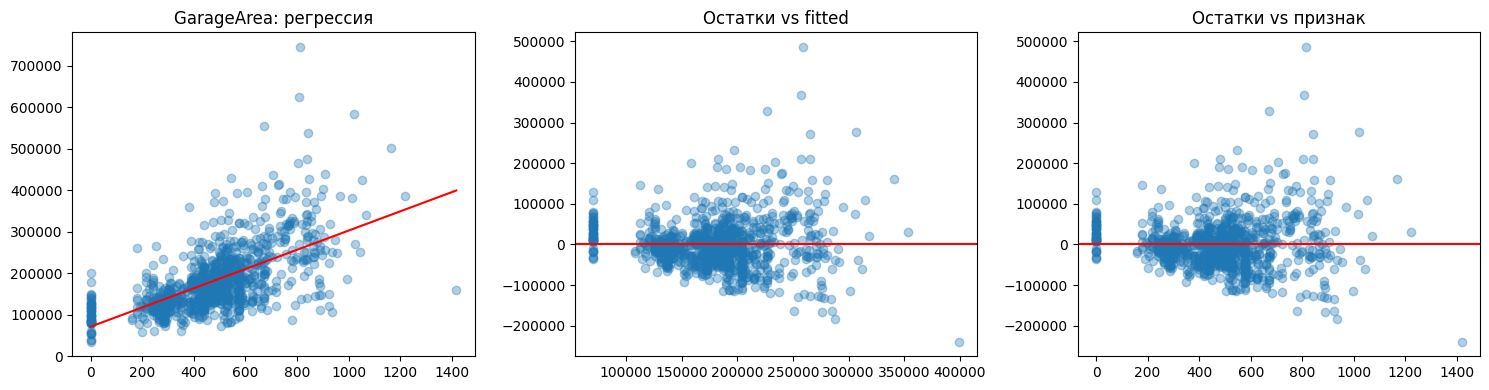


GarageArea: коэффициенты и 95% ДИ


,CI_low,CI_high
const,61489.496213,80144.220147
x1,213.673303,249.504736


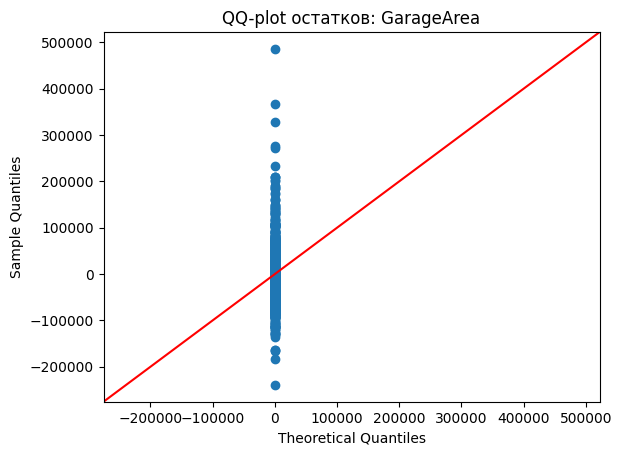

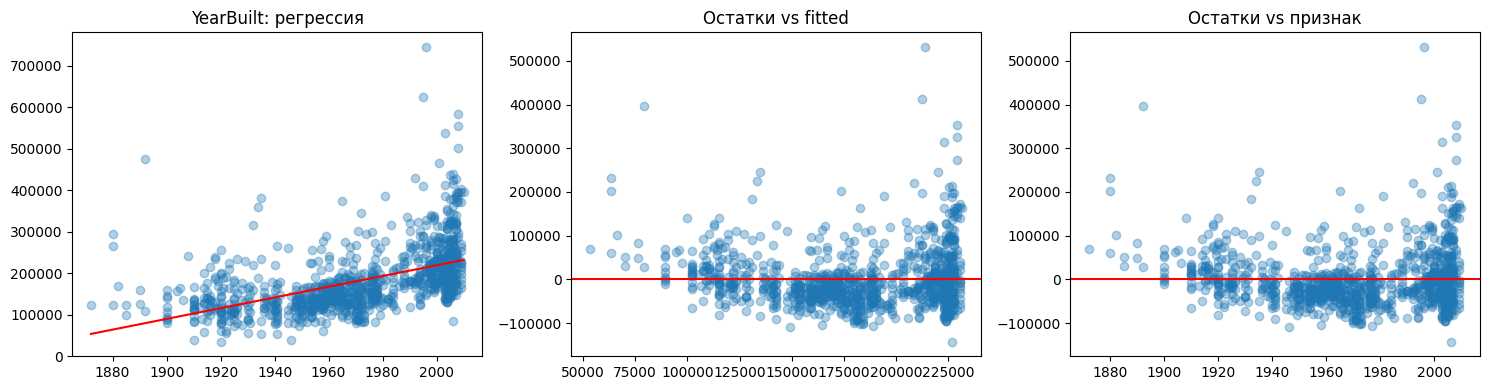


YearBuilt: коэффициенты и 95% ДИ


,CI_low,CI_high
const,-2.629627e+06,-2.104473e+06
x1,1.159728e+03,1.426137e+03


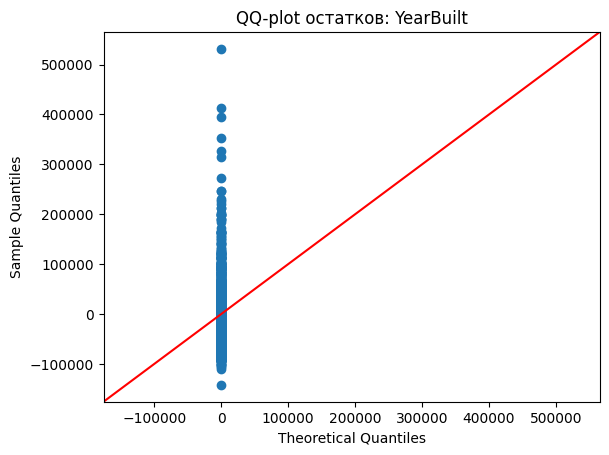

,feature,BP_stat,BP_p,Shapiro_stat,Shapiro_p,Durbin_Watson
0,GrLivArea,240.668090,2.812114e-54,0.907390,2.017082e-24,1.986533
1,OverallQual,71.605077,2.628793e-17,0.916556,2.740476e-23,2.079848
2,GarageArea,64.331174,1.051685e-15,0.913043,9.835834e-24,1.977440
3,YearBuilt,4.836731,2.785966e-02,0.849995,4.869341e-30,2.007086


In [11]:
simple_features = [c for c in ["GrLivArea", "OverallQual", "GarageArea", "YearBuilt"] if c in num_cols]
simple_diagnostics = []
for feat in simple_features:
    med = X_train[feat].median()
    xtr = X_train[feat].fillna(med).to_numpy()
    xte = X_test[feat].fillna(med).to_numpy()
    m = sm.OLS(y_train, sm.add_constant(xtr)).fit()
    pred = m.predict(sm.add_constant(xte))
    resid = y_train.to_numpy() - m.fittedvalues
    bp = het_breuschpagan(resid, m.model.exog)
    shapiro_sample = resid if len(resid) <= 5000 else np.random.default_rng(SEED).choice(resid, 5000, replace=False)
    shapiro = stats.shapiro(shapiro_sample)
    dw = durbin_watson(resid)

    fig, axes = plt.subplots(1, 3, figsize=(15, 4))
    axes[0].scatter(xtr, y_train, alpha=.35)
    order = np.argsort(xtr)
    axes[0].plot(xtr[order], m.fittedvalues.to_numpy()[order], color="red")
    axes[0].set_title(f"{feat}: регрессия")
    axes[1].scatter(m.fittedvalues, resid, alpha=.35)
    axes[1].axhline(0, color="red")
    axes[1].set_title("Остатки vs fitted")
    axes[2].scatter(xtr, resid, alpha=.35)
    axes[2].axhline(0, color="red")
    axes[2].set_title("Остатки vs признак")
    plt.tight_layout()
    plt.show()

    print(f"\n{feat}: коэффициенты и 95% ДИ")
    display(m.conf_int().rename(columns={0:"CI_low",1:"CI_high"}))
    sm.qqplot(resid, line="45")
    plt.title(f"QQ-plot остатков: {feat}")
    plt.show()
    simple_diagnostics.append([feat, bp[0], bp[1], shapiro.statistic, shapiro.pvalue, dw])
display(pd.DataFrame(simple_diagnostics, columns=["feature","BP_stat","BP_p","Shapiro_stat","Shapiro_p","Durbin_Watson"]))

### 3.2. Множественная регрессия: разные наборы признаков

In [12]:
# Набор 1: все признаки; набор 2: исключены очевидно дублирующие пары.
reduced_drop = [c for c in ["GarageCars", "1stFlrSF", "YearRemodAdd"] if c in X.columns]
X_reduced = X.drop(columns=reduced_drop)
Xr_train, Xr_val, yr_train, yr_val = train_test_split(X_reduced, y, test_size=.30, random_state=SEED)

reduced_num_cols = [c for c in num_cols if c not in reduced_drop]
reduced_prep = ColumnTransformer([
    ("num", Pipeline([("imp", SimpleImputer(strategy="median"))]), reduced_num_cols),
    ("cat", Pipeline([("imp", SimpleImputer(strategy="most_frequent")),
                      ("oh", OneHotEncoder(handle_unknown="ignore"))]), cat_cols)
])
configs = {
    "all_onehot": (X_train, X_val, make_preprocessor(encoding="onehot")),
    "reduced_onehot": (Xr_train, Xr_val, reduced_prep)
}
multi_results = []
for name, (xa, xb, prep) in configs.items():
    pipe = Pipeline([("prep", prep), ("model", LinearRegression())])
    pipe.fit(xa, y_train if name=="all_onehot" else yr_train)
    pred = pipe.predict(xb)
    target_val = y_val if name=="all_onehot" else yr_val
    multi_results.append([name, mean_squared_error(target_val,pred)**0.5,
                          mean_absolute_error(target_val,pred), r2_score(target_val,pred)])
display(pd.DataFrame(multi_results, columns=["configuration","RMSE","MAE","R2"]))

,configuration,RMSE,MAE,R2
0,all_onehot,28483.68109,21479.185172,0.870830
1,reduced_onehot,31009.59976,21061.593493,0.862198


### 3.3. Важность признаков: стандартизованные коэффициенты, t/p, permutation и SHAP для линейной модели

,abs_std_coef,abs_t,p_value,permutation,SHAP_mean_abs
OverallQual,NaN,NaN,NaN,26086.989401,23438.041995
GrLivArea,NaN,NaN,NaN,17074.233380,18762.491429
GarageCars,NaN,NaN,NaN,3762.596978,8241.333447
TotalBsmtSF,NaN,NaN,NaN,3352.220399,5567.848896
YearBuilt,NaN,NaN,NaN,2987.743180,9390.946276
LotArea,NaN,NaN,NaN,1604.329740,2565.622636
GarageArea,NaN,NaN,NaN,138.279391,950.748104
FullBath,NaN,NaN,NaN,96.207583,2355.170137


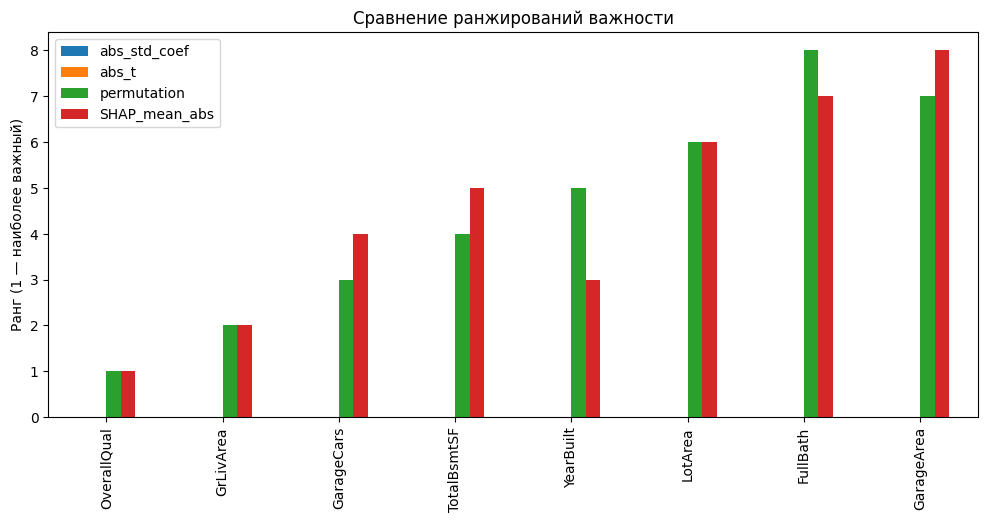

In [13]:
# Для интерпретируемого числового набора без категорий.
imp_features = [c for c in ["OverallQual","GrLivArea","GarageCars","TotalBsmtSF","YearBuilt",
                            "LotArea","FullBath","GarageArea"] if c in num_cols]
imp_prep = Pipeline([("imputer", SimpleImputer(strategy="median")), ("scaler", StandardScaler())])
Z = imp_prep.fit_transform(X_train[imp_features])
ols_imp = sm.OLS(y_train, sm.add_constant(Z)).fit()
std_coef = pd.Series(ols_imp.params[1:], index=imp_features, name="standardized_coef")
t_stats = pd.Series(ols_imp.tvalues[1:], index=imp_features, name="t_stat")
p_values = pd.Series(ols_imp.pvalues[1:], index=imp_features, name="p_value")

perm_model = Pipeline([("prep", ColumnTransformer([("num", imp_prep, imp_features)])),
                       ("model", LinearRegression())])
perm_model.fit(X_train[imp_features], y_train)
perm = permutation_importance(perm_model, X_val[imp_features], y_val,
                              n_repeats=20, random_state=SEED, scoring="neg_root_mean_squared_error")
perm_imp = pd.Series(perm.importances_mean, index=imp_features, name="permutation")

# Для линейной модели при background mean: |coef_j * (x_j - mean_j)| — локальный вклад SHAP.
shap_global = pd.Series(np.mean(np.abs(Z * np.asarray(ols_imp.params[1:])), axis=0),
                        index=imp_features, name="SHAP_mean_abs")
importance = pd.concat([std_coef.abs().rename("abs_std_coef"),
                        t_stats.abs().rename("abs_t"),
                        p_values.rename("p_value"),
                        perm_imp, shap_global], axis=1)
display(importance.sort_values("permutation", ascending=False))
importance[["abs_std_coef","abs_t","permutation","SHAP_mean_abs"]].rank(ascending=False).plot(kind="bar", figsize=(12,5))
plt.title("Сравнение ранжирований важности")
plt.ylabel("Ранг (1 — наиболее важный)")
plt.show()

### 3.4. C1 — проверка гипотезы о VIF > 10

In [14]:
# Сопоставим стандартизованные коэффициенты и permutation importance на числовом наборе.
c1 = importance[["abs_std_coef","permutation"]].copy()
c1["VIF"] = vif_frame.set_index("feature")["VIF"].reindex(c1.index)
c1["VIF_gt_10"] = c1["VIF"] > 10
display(c1.sort_values("VIF", ascending=False))
print("Если при VIF > 10 коэффициентные ранги расходятся с permutation/SHAP и bootstrap-разброс растёт, это поддерживает C1.")
print("VIF сам по себе не задаёт универсальную границу важности: вывод зависит от корреляций и выбранного набора признаков.")

,abs_std_coef,permutation,VIF,VIF_gt_10
YearBuilt,NaN,2987.743180,8090.886754,True
OverallQual,NaN,26086.989401,48.084196,True
GarageCars,NaN,3762.596978,34.967504,True
GarageArea,NaN,138.279391,30.527081,True
TotalBsmtSF,NaN,3352.220399,24.715726,True
GrLivArea,NaN,17074.233380,24.060835,True
FullBath,NaN,96.207583,18.085340,True
LotArea,NaN,1604.329740,2.159355,False


Если при VIF > 10 коэффициентные ранги расходятся с permutation/SHAP и bootstrap-разброс растёт, это поддерживает C1.
VIF сам по себе не задаёт универсальную границу важности: вывод зависит от корреляций и выбранного набора признаков.


## 4. Нормализация и регуляризация

### 4.1. D1 — стандартизация и эквивалентность МНК

In [15]:
scale_features = [c for c in ["GrLivArea","OverallQual","GarageArea","YearBuilt","LotArea"] if c in num_cols]
Xtr = X_train[scale_features].fillna(X_train[scale_features].median())
Xte = X_test[scale_features].fillna(X_train[scale_features].median())
raw_lr = LinearRegression().fit(Xtr, y_train)
scaler = StandardScaler().fit(Xtr)
Ztr, Zte = scaler.transform(Xtr), scaler.transform(Xte)
scaled_lr = LinearRegression().fit(Ztr, y_train)

# Пересчёт коэффициентов стандартизованной модели к исходной шкале.
coef_back = scaled_lr.coef_ / scaler.scale_
intercept_back = scaled_lr.intercept_ - np.sum(scaled_lr.coef_ * scaler.mean_ / scaler.scale_)
print("Коэффициенты raw:", raw_lr.coef_)
print("Коэффициенты после обратного пересчёта:", coef_back)
print("Свободный член raw / пересчитанный:", raw_lr.intercept_, intercept_back)
print("Максимальная разница предсказаний:",
      np.max(np.abs(raw_lr.predict(Xte) - scaled_lr.predict(Zte))))

Коэффициенты raw: [4.70289649e+01 2.35759585e+04 5.30201287e+01 4.09647678e+02
 7.58389824e-01]
Коэффициенты после обратного пересчёта: [4.70289649e+01 2.35759585e+04 5.30201287e+01 4.09647678e+02
 7.58389824e-01]
Свободный член raw / пересчитанный: -875943.5079141534 -875943.5079141634
Максимальная разница предсказаний: 7.677590474486351e-08


### 4.2. StandardScaler, MinMaxScaler, RobustScaler

In [16]:
scaler_results = []
for scaler_obj, scaler_name in [(StandardScaler(),"StandardScaler"),
                                (MinMaxScaler(),"MinMaxScaler"),
                                (RobustScaler(),"RobustScaler")]:
    pipe = Pipeline([
        ("prep", make_preprocessor(scaler=scaler_obj)),
        ("model", LinearRegression())
    ])
    pipe.fit(X_train, y_train)
    pred = pipe.predict(X_val)
    # Обусловленность только по числовой части после соответствующего масштабирования.
    numeric_imp = SimpleImputer(strategy="median").fit_transform(X_train[num_cols])
    transformed = scaler_obj.fit_transform(numeric_imp)
    cond = np.linalg.cond(transformed)
    scaler_results.append([scaler_name, mean_squared_error(y_val,pred)**0.5,
                           mean_absolute_error(y_val,pred), r2_score(y_val,pred), cond])
display(pd.DataFrame(scaler_results, columns=["scaler","RMSE","MAE","R2","condition_number"]))

,scaler,RMSE,MAE,R2,condition_number
0,StandardScaler,26876.729154,18157.023891,0.884994,1.655546e+16
1,MinMaxScaler,26877.608094,18157.582319,0.884986,9.005733e+16
2,RobustScaler,26593.289239,18114.310894,0.887406,2.858459e+18


### 4.3. D2 — Ridge/Lasso в режимах n≫p, n≈p, n≪p

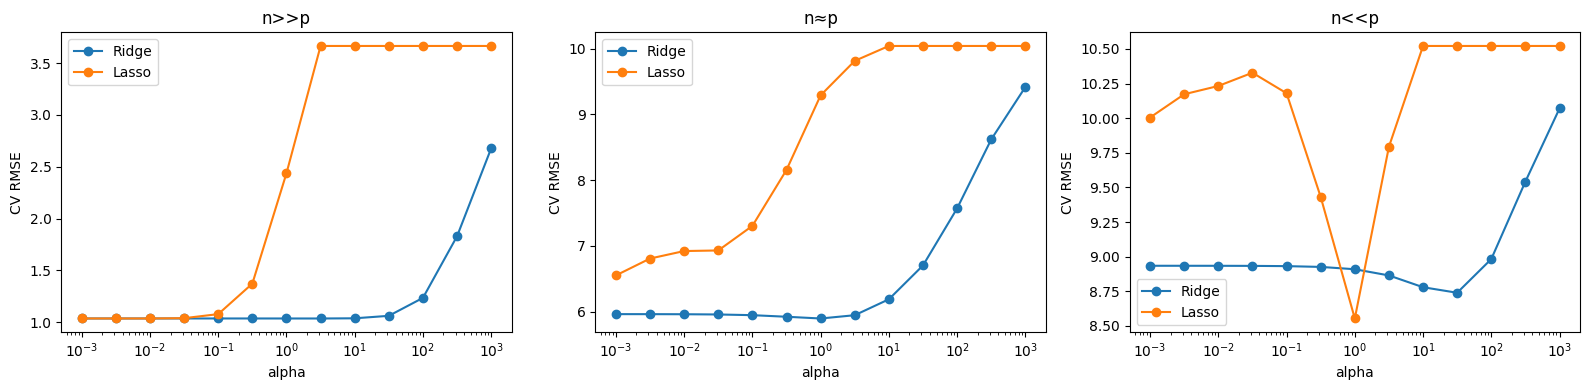

,regime,model,alpha_star,CV_RMSE
0,n>>p,Ridge,3.162278,1.034999
1,n>>p,Lasso,0.010000,1.035105
2,n≈p,Ridge,1.000000,5.894636
3,n≈p,Lasso,0.001000,6.549919
4,n<<p,Ridge,31.622777,8.739438
5,n<<p,Lasso,1.000000,8.553664


Теоретическое ожидание: регуляризация особенно полезна при p близком к n, p>n и/или мультиколлинеарности.


In [17]:
# Режимы создаются на стандартизованных числовых матрицах разной размерности.
# Сравнение иллюстрирует влияние отношения n/p и мультиколлинеарности.
rng = np.random.default_rng(SEED)
def synthetic_regime(n, p, correlated=False):
    Z = rng.normal(size=(n,p))
    if correlated and p > 1:
        Z[:,1] = Z[:,0] + rng.normal(scale=.05, size=n)
    beta = rng.normal(size=p)
    target = Z @ beta + rng.normal(scale=1.0, size=n)
    return Z, target

regimes = {"n>>p": (600,10,False), "n≈p": (100,100,False), "n<<p": (60,120,True)}
alphas = np.logspace(-3, 3, 13)
regime_rows = []
fig, axes = plt.subplots(1,3,figsize=(16,4))
for ax, (regime, (n,p,cor)) in zip(axes, regimes.items()):
    Zs, ys = synthetic_regime(n,p,cor)
    cv = KFold(n_splits=5, shuffle=True, random_state=SEED)
    for model_name, estimator in [("Ridge", Ridge()), ("Lasso", Lasso(max_iter=20000))]:
        means = []
        for alpha in alphas:
            scores = []
            for tr, va in cv.split(Zs):
                est = clone(estimator).set_params(alpha=alpha)
                est.fit(Zs[tr], ys[tr])
                scores.append(mean_squared_error(ys[va], est.predict(Zs[va]))**0.5)
            means.append(np.mean(scores))
        best_idx = int(np.argmin(means))
        regime_rows.append([regime, model_name, alphas[best_idx], means[best_idx]])
        ax.plot(alphas, means, marker="o", label=model_name)
    ax.set_xscale("log"); ax.set_title(regime); ax.set_xlabel("alpha"); ax.set_ylabel("CV RMSE"); ax.legend()
plt.tight_layout(); plt.show()
display(pd.DataFrame(regime_rows, columns=["regime","model","alpha_star","CV_RMSE"]))
print("Теоретическое ожидание: регуляризация особенно полезна при p близком к n, p>n и/или мультиколлинеарности.")

## 5. Статистическая оценка качества и анализ ошибок

### 5.1. RepeatedKFold 5×5: пять конфигураций на одних фолдах

,model,metric,mean,std,SEM,CI95_low,CI95_high,min,max
0,Lasso_onehot,RMSE,31117.653024,9003.178509,1800.635702,27401.323589,34833.982459,18531.513420,53525.233434
1,Lasso_onehot,MAE,16604.328215,1545.019370,309.003874,15966.575564,17242.080866,12851.010547,19336.077386
2,Lasso_onehot,R2,0.832346,0.107898,0.021580,0.787808,0.876884,0.481425,0.926063
3,OLS_onehot,RMSE,33827.496274,7678.257180,1535.651436,30658.067485,36996.925064,22192.287887,54161.327438
4,OLS_onehot,MAE,19295.371124,1373.379574,274.675915,18728.467898,19862.274349,15666.796660,21264.146591
5,OLS_onehot,R2,0.807631,0.098952,0.019790,0.766786,0.848477,0.469026,0.894008
6,OLS_ordinal,RMSE,37543.166327,9563.870272,1912.774054,33595.394707,41490.937947,23158.259213,61170.477457
7,OLS_ordinal,MAE,20664.601900,1519.828939,303.965788,20037.247348,21291.956452,16943.783873,23235.232943
8,OLS_ordinal,R2,0.756169,0.150880,0.030176,0.693889,0.818450,0.281411,0.884017
9,OLS_strong_numeric,RMSE,39003.873073,6536.019720,1307.203944,36305.936734,41701.809413,28041.536453,55509.545786


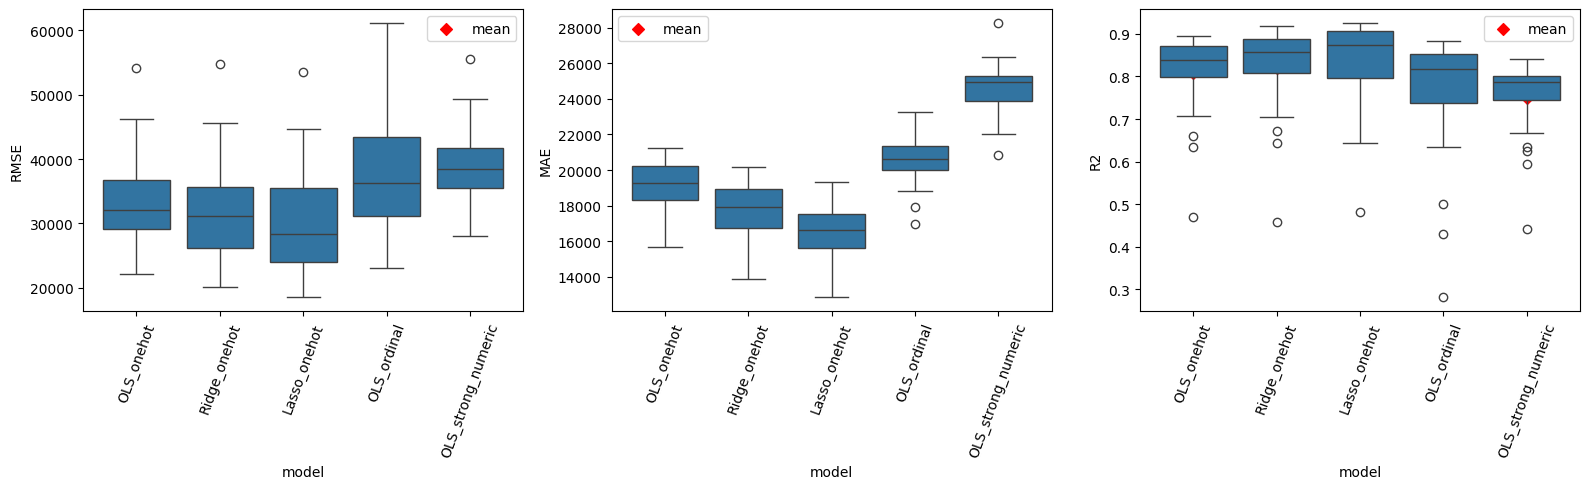

In [18]:
# Для практического сравнения используются одинаковые фолды и одинаковые preprocessing pipelines.
# Конфигурации: линейная, Ridge, Lasso, ordinal, только сильные числовые признаки.
rkf = RepeatedKFold(n_splits=5, n_repeats=5, random_state=SEED)
splits = list(rkf.split(X, y))

strong_num = [c for c in ["OverallQual","GrLivArea","GarageCars","TotalBsmtSF","YearBuilt",
                          "GarageArea","FullBath","1stFlrSF"] if c in num_cols]
strong_prep = ColumnTransformer([("num", Pipeline([
    ("imp", SimpleImputer(strategy="median")), ("scale", StandardScaler())
]), strong_num)])

cv_models = {
    "OLS_onehot": Pipeline([("prep", make_preprocessor()), ("model", LinearRegression())]),
    "Ridge_onehot": Pipeline([("prep", make_preprocessor(scaler=StandardScaler())), ("model", Ridge(alpha=10))]),
    "Lasso_onehot": Pipeline([("prep", make_preprocessor(scaler=StandardScaler())), ("model", Lasso(alpha=100, max_iter=20000))]),
    "OLS_ordinal": Pipeline([("prep", make_preprocessor(encoding="ordinal")), ("model", LinearRegression())]),
    "OLS_strong_numeric": Pipeline([("prep", strong_prep), ("model", LinearRegression())])
}

cv_records = []
for fold_id, (tr, va) in enumerate(splits):
    Xtr_fold, Xva_fold = X.iloc[tr], X.iloc[va]
    ytr_fold, yva_fold = y.iloc[tr], y.iloc[va]
    for model_name, estimator in cv_models.items():
        fitted = clone(estimator).fit(Xtr_fold, ytr_fold)
        pred = fitted.predict(Xva_fold)
        cv_records.append([fold_id, model_name,
                           mean_squared_error(yva_fold,pred)**0.5,
                           mean_absolute_error(yva_fold,pred),
                           r2_score(yva_fold,pred)])
cv_scores = pd.DataFrame(cv_records, columns=["fold","model","RMSE","MAE","R2"])

def metric_summary(values):
    values = np.asarray(values)
    n = len(values); mean = values.mean(); sd = values.std(ddof=1)
    sem = sd / np.sqrt(n)
    half = stats.t.ppf(.975, n-1) * sem
    return pd.Series({"mean":mean, "std":sd, "SEM":sem,
                      "CI95_low":mean-half, "CI95_high":mean+half,
                      "min":values.min(), "max":values.max()})

summary_rows = []
for model_name, group in cv_scores.groupby("model"):
    for metric in ["RMSE","MAE","R2"]:
        s = metric_summary(group[metric])
        summary_rows.append([model_name, metric] + s.tolist())
cv_summary = pd.DataFrame(summary_rows, columns=["model","metric","mean","std","SEM","CI95_low","CI95_high","min","max"])
display(cv_summary)

fig, axes = plt.subplots(1,3,figsize=(16,5))
for ax, metric in zip(axes, ["RMSE","MAE","R2"]):
    sns.boxplot(data=cv_scores, x="model", y=metric, ax=ax)
    means = cv_scores.groupby("model")[metric].mean()
    ax.scatter(range(len(means)), means.reindex([t.get_text() for t in ax.get_xticklabels()]),
               color="red", marker="D", label="mean")
    ax.tick_params(axis="x", rotation=70)
    ax.legend()
plt.tight_layout(); plt.show()

### 5.2. Парные сравнения на одних фолдах: Shapiro, paired t/Wilcoxon, Holm

In [19]:
from statsmodels.stats.multitest import multipletests

pairs = [("OLS_onehot","Ridge_onehot"),
         ("OLS_onehot","Lasso_onehot"),
         ("OLS_onehot","OLS_ordinal"),
         ("OLS_onehot","OLS_strong_numeric")]
pair_rows = []
raw_p = []
for a,b in pairs:
    aa = cv_scores[cv_scores.model==a].sort_values("fold")["RMSE"].to_numpy()
    bb = cv_scores[cv_scores.model==b].sort_values("fold")["RMSE"].to_numpy()
    d = aa - bb
    sh = stats.shapiro(d)
    if sh.pvalue >= .05:
        test_name = "paired t-test"
        stat, pval = stats.ttest_rel(aa,bb)
    else:
        test_name = "Wilcoxon"
        stat, pval = stats.wilcoxon(d)
    mean_d = d.mean()
    sem_d = d.std(ddof=1)/np.sqrt(len(d))
    half = stats.t.ppf(.975,len(d)-1)*sem_d
    cohens_d = mean_d/(d.std(ddof=1)+1e-12)
    pair_rows.append([a+" vs "+b, mean_d, mean_d-half, mean_d+half, test_name, pval, cohens_d])
    raw_p.append(pval)
adjusted = multipletests(raw_p, method="holm")[1]
pair_table = pd.DataFrame(pair_rows, columns=["pair","delta_RMSE_A_minus_B","CI95_low","CI95_high","test","p_raw","Cohen_d"])
pair_table["p_Holm"] = adjusted
pair_table["verdict"] = np.where(pair_table.p_Holm<.05, "статистически значимое различие", "значимое различие не обнаружено")
display(pair_table)

,pair,delta_RMSE_A_minus_B,CI95_low,CI95_high,test,p_raw,Cohen_d,p_Holm,verdict
0,OLS_onehot vs Ridge_onehot,1293.802160,795.713482,1791.890837,paired t-test,1.670577e-05,1.072209,3.341155e-05,статистически значимое различие
1,OLS_onehot vs Lasso_onehot,2709.843250,1849.457283,3570.229218,paired t-test,1.008877e-06,1.300077,3.026632e-06,статистически значимое различие
2,OLS_onehot vs OLS_ordinal,-3715.670053,-6765.157871,-666.182234,Wilcoxon,5.388260e-05,-0.502954,5.388260e-05,статистически значимое различие
3,OLS_onehot vs OLS_strong_numeric,-5176.376799,-6047.911176,-4304.842422,paired t-test,8.032543e-12,-2.451657,3.213017e-11,статистически значимое различие


### 5.3. Анализ ошибок лучшей модели по подгруппам + bootstrap 95% ДИ

Лучшая CV-конфигурация: Lasso_onehot
Test RMSE: 29809.436663852764 | MAE: 17342.29725332432 | R2: 0.883237137393712


,feature,group,n,RMSE,MAE,RMSE_CI_low,RMSE_CI_high
183,Fireplaces,"(1.0, 3.0]",13,86908.021741,60550.090048,40384.158624,123278.473856
181,TotRmsAbvGrd,"(8.0, 12.0]",17,79150.964691,54005.690112,38134.963732,112519.359731
191,GarageCars,"(2.0, 4.0]",20,72401.244503,46046.712437,30337.005138,101820.595664
77,KitchenQual,Other,27,69718.887700,46518.587498,41553.076193,96766.244312
124,OverallQual,"(7.0, 10.0]",24,69093.764635,44671.124595,36683.743114,96091.128453
53,BsmtQual,Other,25,64503.248724,39109.266034,27830.573380,92071.806302
58,BsmtExposure,Other,23,63207.869596,37322.463169,20556.311003,92045.181189
84,FireplaceQu,Other,13,59783.577199,29341.121422,11077.494255,99588.683596
221,predicted_quantile,"(212081.151, 552336.339]",44,57854.676839,36653.704065,35485.291997,77059.426492
44,MasVnrType,Other,16,57472.458394,30662.105897,13690.605069,88165.084032


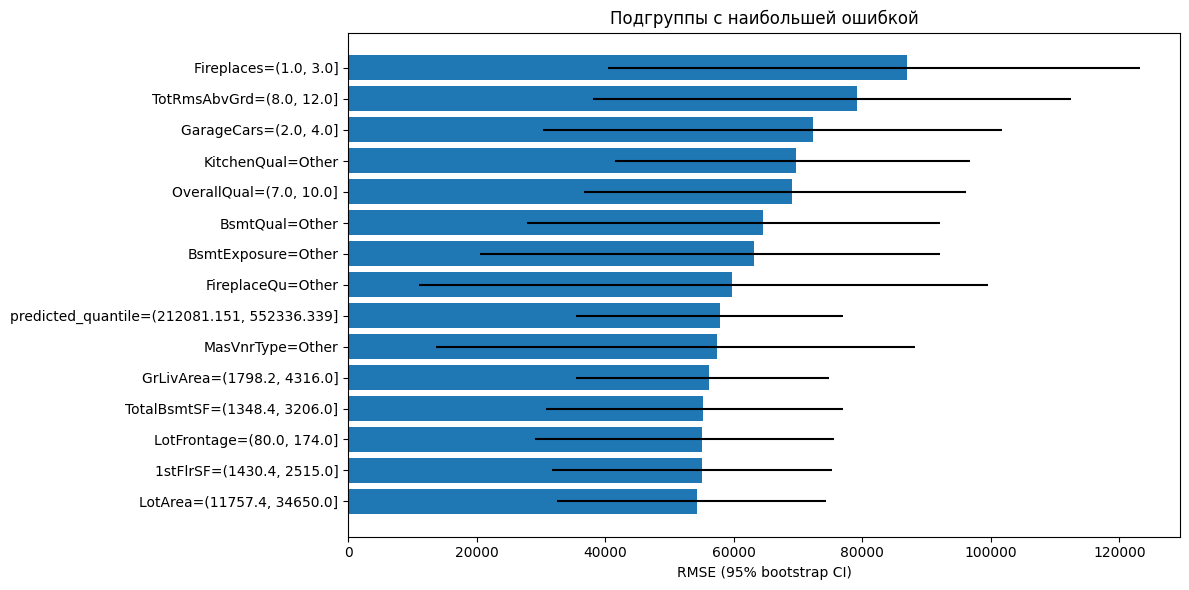

In [20]:
# Выбираем модель с минимальным средним RMSE по CV, затем оцениваем на held-out test.
best_name = cv_summary[cv_summary.metric=="RMSE"].sort_values("mean").iloc[0]["model"]
best_model = clone(cv_models[best_name]).fit(X_train, y_train)
test_pred = best_model.predict(X_test)
test_resid = y_test.to_numpy() - test_pred
print("Лучшая CV-конфигурация:", best_name)
print("Test RMSE:", mean_squared_error(y_test,test_pred)**0.5,
      "| MAE:", mean_absolute_error(y_test,test_pred),
      "| R2:", r2_score(y_test,test_pred))

def bootstrap_metric_ci(y_true, y_pred, n_boot=1000, seed=SEED):
    yt = np.asarray(y_true); yp = np.asarray(y_pred)
    rng = np.random.default_rng(seed)
    n = len(yt); vals = []
    for _ in range(n_boot):
        idx = rng.integers(0,n,n)
        vals.append(mean_squared_error(yt[idx],yp[idx])**0.5)
    return np.quantile(vals,[.025,.975])

test_frame = X_test.copy()
test_frame["actual"] = y_test
test_frame["predicted"] = test_pred
test_frame["abs_error"] = np.abs(test_resid)
subgroup_rows = []

# Категориальные признаки: самые распространённые категории, редкие объединяются.
for col in cat_cols:
    counts = test_frame[col].fillna("__MISSING__").value_counts()
    common = counts[counts>=20].index
    groups = test_frame[col].fillna("__MISSING__").where(test_frame[col].fillna("__MISSING__").isin(common), "Other")
    for level in groups.unique():
        mask = groups.to_numpy()==level
        if mask.sum()<10: continue
        yt = test_frame.loc[mask,"actual"].to_numpy()
        yp = test_frame.loc[mask,"predicted"].to_numpy()
        lo,hi = bootstrap_metric_ci(yt,yp)
        subgroup_rows.append([col,str(level),int(mask.sum()),mean_squared_error(yt,yp)**0.5,
                              mean_absolute_error(yt,yp),lo,hi])

# Непрерывные признаки: 5 квантильных групп.
for col in num_cols:
    try:
        bins = pd.qcut(test_frame[col], q=5, duplicates="drop")
        for level in bins.cat.categories:
            mask = (bins==level).to_numpy()
            if mask.sum()<10: continue
            yt = test_frame.loc[mask,"actual"].to_numpy()
            yp = test_frame.loc[mask,"predicted"].to_numpy()
            lo,hi = bootstrap_metric_ci(yt,yp)
            subgroup_rows.append([col,str(level),int(mask.sum()),mean_squared_error(yt,yp)**0.5,
                                  mean_absolute_error(yt,yp),lo,hi])
    except Exception:
        pass

# Подгруппы по квантилям предсказания.
pred_bins = pd.qcut(test_frame["predicted"], q=5, duplicates="drop")
for level in pred_bins.cat.categories:
    mask = (pred_bins==level).to_numpy()
    yt = test_frame.loc[mask,"actual"].to_numpy()
    yp = test_frame.loc[mask,"predicted"].to_numpy()
    lo,hi = bootstrap_metric_ci(yt,yp)
    subgroup_rows.append(["predicted_quantile",str(level),int(mask.sum()),
                          mean_squared_error(yt,yp)**0.5,mean_absolute_error(yt,yp),lo,hi])

subgroups = pd.DataFrame(subgroup_rows, columns=["feature","group","n","RMSE","MAE","RMSE_CI_low","RMSE_CI_high"])
display(subgroups.sort_values("RMSE",ascending=False).head(25))
worst = subgroups.sort_values("RMSE",ascending=False).head(15)
plt.figure(figsize=(12,6))
plt.barh(worst["feature"]+"="+worst["group"].astype(str), worst["RMSE"],
         xerr=[worst["RMSE"]-worst["RMSE_CI_low"], worst["RMSE_CI_high"]-worst["RMSE"]])
plt.xlabel("RMSE (95% bootstrap CI)")
plt.title("Подгруппы с наибольшей ошибкой")
plt.gca().invert_yaxis(); plt.tight_layout(); plt.show()

### 5.4. Диагностика предпосылок МНК: остатки, BP, White, Shapiro, DW, RESET

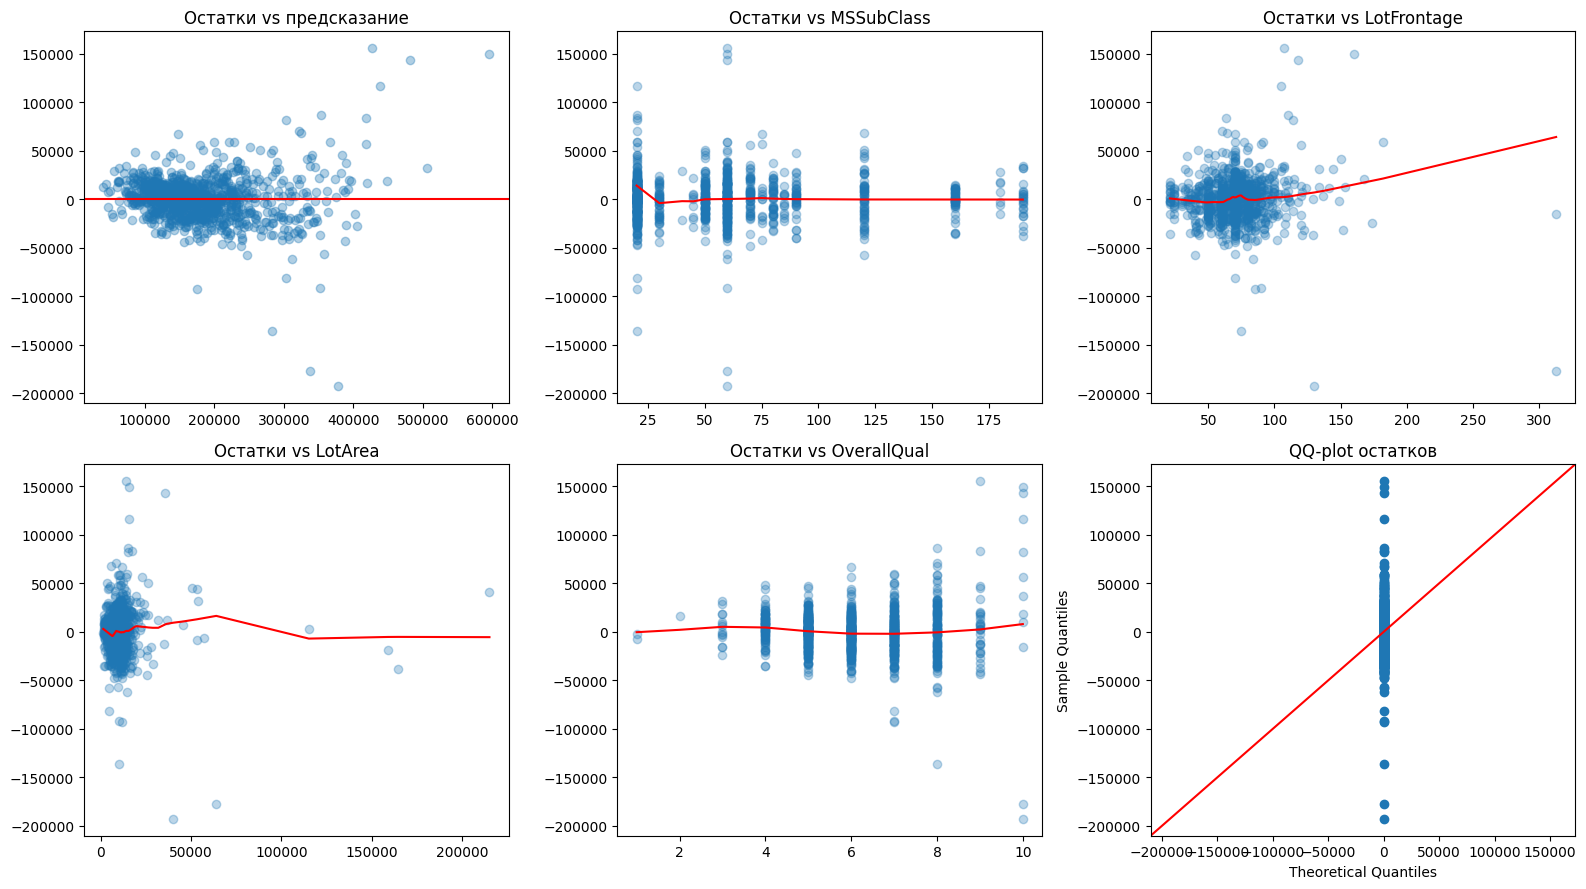

,test,statistic,p_value,verdict
0,Breusch-Pagan,337.352451,7.999689e-70,гетероскедастичность
1,White,838.273839,3.392973e-159,гетероскедастичность
2,Shapiro-Wilk,0.815377,1.200326e-32,ненормальность
3,Durbin-Watson,2.022106,NaN,"около 2, тревожного сигнала нет"
4,RESET,11.452169,7.414437e-04,возможная нелинейность


<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:              SalePrice   R-squared:                       0.750
Model:                            OLS   Adj. R-squared:                  0.749
Method:                 Least Squares   F-statistic:                     235.0
Date:                Mon, 09 Nov 2026   Prob (F-statistic):          4.97e-188
Time:                        23:04:18   Log-Likelihood:                -12248.
No. Observations:                1022   AIC:                         2.451e+04
Df Residuals:                    1015   BIC:                         2.454e+04
Df Model:                           6                                         
Covariance Type:                  HC3                                         
==============================================================================
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const       1.813e+05   1272.496    142.486      0.000    1.79e+05    1.84e+05
x1          2.821e+04   3534.757      7.981      0.000    2.13e+04    3.51e+04
x2          2.516e+04   5034.369      4.997      0.000    1.53e+04     3.5e+04
x3           1.04e+04   9034.982      1.151      0.250   -7327.407    2.81e+04
x4          9808.5863   6594.220      1.487      0.137   -3131.278    2.27e+04
x5          9870.9304   1672.345      5.902      0.000    6589.282    1.32e+04
x6          1952.0206   7083.945      0.276      0.783   -1.19e+04    1.59e+04
==============================================================================
Omnibus:                      322.863   Durbin-Watson:                   2.022
Prob(Omnibus):                  0.000   Jarque-Bera (JB):            25441.463
Skew:                          -0.472   Prob(JB):                         0.00
Kurtosis:                      27.425   Cond. No.                         5.65
==============================================================================

Notes:
[1] Standard Errors are heteroscedasticity robust (HC3)
"""

In [21]:
# Диагностика проводится на train для анализа предпосылок; тестовая выборка остаётся финальной оценкой.
diag_model = Pipeline([("prep", make_preprocessor()), ("model", LinearRegression())])
diag_model.fit(X_train, y_train)
train_fit = diag_model.predict(X_train)
train_resid = y_train.to_numpy() - train_fit

fig, axes = plt.subplots(2,3,figsize=(16,9))
axes[0,0].scatter(train_fit,train_resid,alpha=.35); axes[0,0].axhline(0,color="red")
axes[0,0].set_title("Остатки vs предсказание")
for ax, col in zip(axes.flat[1:5], [c for c in num_cols if c in X_train.columns][:4]):
    vals = X_train[col].fillna(X_train[col].median())
    ax.scatter(vals,train_resid,alpha=.3)
    smoothed = lowess(train_resid, vals, frac=.35, return_sorted=True)
    ax.plot(smoothed[:,0],smoothed[:,1],color="red")
    ax.set_title(f"Остатки vs {col}")
sm.qqplot(train_resid, line="45", ax=axes[1,2])
axes[1,2].set_title("QQ-plot остатков")
plt.tight_layout(); plt.show()

# Тесты на числовом подмножестве (устойчивая интерпретируемая OLS-модель).
diag_cols = [c for c in ["OverallQual","GrLivArea","GarageCars","TotalBsmtSF","YearBuilt","GarageArea"] if c in num_cols]
diag_X = SimpleImputer(strategy="median").fit_transform(X_train[diag_cols])
diag_X = sm.add_constant(StandardScaler().fit_transform(diag_X))
ols_diag = sm.OLS(y_train, diag_X).fit()
resid = ols_diag.resid
bp = het_breuschpagan(resid, ols_diag.model.exog)
white = het_white(resid, ols_diag.model.exog)
shapiro = stats.shapiro(resid if len(resid)<=5000 else np.random.default_rng(SEED).choice(resid,5000,replace=False))
dw = durbin_watson(resid)
reset = linear_reset(ols_diag, power=2, use_f=True)

diag_table = pd.DataFrame([
    ["Breusch-Pagan",bp[0],bp[1],"гетероскедастичность" if bp[1]<.05 else "нет оснований отвергнуть гомоскедастичность"],
    ["White",white[0],white[1],"гетероскедастичность" if white[1]<.05 else "нет оснований отвергнуть гомоскедастичность"],
    ["Shapiro-Wilk",shapiro.statistic,shapiro.pvalue,"ненормальность" if shapiro.pvalue<.05 else "нет оснований отвергнуть нормальность"],
    ["Durbin-Watson",dw,np.nan,"тревога" if (dw<1.5 or dw>2.5) else "около 2, тревожного сигнала нет"],
    ["RESET",float(reset.fvalue),float(reset.pvalue),"возможная нелинейность" if reset.pvalue<.05 else "нет оснований отвергнуть линейную спецификацию"]
],columns=["test","statistic","p_value","verdict"])
display(diag_table)

# Robust HC3 standard errors для коэффициентов числовой модели.
display(ols_diag.get_robustcov_results(cov_type="HC3").summary())

## 6. Итог по гипотезам A1, B1, C1, D1, D2

In [22]:
# Сводка численных результатов, автоматически полученных в предыдущих разделах.
hypothesis_summary = pd.DataFrame([
    ["A1", "Удаление выбросов улучшает RMSE",
     f"RMSE all={rmse_all:.2f}; RMSE trim={rmse_trim:.2f}; Δ={rmse_trim-rmse_all:.2f}",
     "Подтверждена, если Δ<0; иначе опровергнута на данном split. Удалять только доказанные ошибки."],
    ["B1", "Биннинг полезнее при немонотонной зависимости",
     "Сопоставить Spearman rho остатков и RMSE raw/binning в таблице B1",
     "Частично проверяется на выбранных признаках; биннинг может помочь при пороговых/немонотонных эффектах, но теряет информацию."],
    ["C1", "При VIF>10 стандартизованные коэффициенты теряют надёжность",
     "См. VIF, bootstrap-разброс коэффициентов и сравнение рангов важности",
     "Подтверждается при высоком VIF и нестабильных коэффициентах/расхождении рангов; VIF не является мерой предсказательной важности."],
    ["D1", "Стандартизация не меняет оптимум МНК",
     "См. разницу предсказаний и обратный пересчёт коэффициентов",
     "Подтверждается, если предсказания совпадают с точностью вычислений; меняется шкала коэффициентов и обусловленность."],
    ["D2", "Ridge/Lasso помогают при мультиколлинеарности или малом n/p",
     "См. alpha* и CV RMSE для n>>p, n≈p, n<<p",
     "Подтверждается, если выигрыш проявляется главным образом при n≈p/n<<p или корреляции; не является универсальным правилом."]
], columns=["hypothesis","statement","evidence","verdict_and_conditions"])
display(hypothesis_summary)

,hypothesis,statement,evidence,verdict_and_conditions
0,A1,Удаление выбросов улучшает RMSE,RMSE all=32566.47; RMSE trim=40442.11; Δ=7875.64,"Подтверждена, если Δ<0; иначе опровергнута на ..."
1,B1,Биннинг полезнее при немонотонной зависимости,Сопоставить Spearman rho остатков и RMSE raw/b...,Частично проверяется на выбранных признаках; б...
2,C1,При VIF>10 стандартизованные коэффициенты теря...,"См. VIF, bootstrap-разброс коэффициентов и сра...",Подтверждается при высоком VIF и нестабильных ...
3,D1,Стандартизация не меняет оптимум МНК,См. разницу предсказаний и обратный пересчёт к...,"Подтверждается, если предсказания совпадают с ..."
4,D2,Ridge/Lasso помогают при мультиколлинеарности ...,"См. alpha* и CV RMSE для n>>p, n≈p, n<<p","Подтверждается, если выигрыш проявляется главн..."
